In [ ]:
# =============================================
# IMPORT
# =============================================
from utility.logger             import aiLogger
from keras.callbacks            import EarlyStopping, ReduceLROnPlateau
from model.componentModel       import mainModel
from model.tepSystemModel       import SystemModel
from preProcessingDataTurbofan  import PreProcessData
from prettytable                import PrettyTable

from keras.optimizers           import Adam
from utility.matpilotDraw       import MatPlot
from sklearn.preprocessing      import MinMaxScaler

import tensorflow               as tf
import pandas                   as pd
import matplotlib.pyplot        as plt
import numpy                    as np
import os, warnings
import random
import json


2025-02-17 10:53:16.388884: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-02-17 10:53:16.496245: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-02-17 10:53:16.496260: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-02-17 10:53:16.520742: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-17 10:53:17.150848: W tensorflow/stream_executor/platform/de

In [ ]:
# ---------------------------
# Loading config file
# ---------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    configData = json.load(configFile)
config = configData["turbofan"]  

# ---------------------------
# Set debug level and 
# ---------------------------
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 

os.environ["CUDA_VISIBLE_DEVICES"] = "0" 
np.random.seed(1)
random.seed(1)
tf.random.set_seed(1)

outputDir               = os.path.expanduser(config["dataDir"])
totalTraject            = 2
normalizeHI             = True
showRedundantShutdown   = False

#### Preprocessing data

In [ ]:
# ==============================
# Config and data preprocessing
# ==============================
preData             = PreProcessData(config=config)
outputDir           = os.path.expanduser(preData.config["dataDir"])
rawData             = preData.loadDataFromTxtFormat(dir = outputDir, name="data/df_train.txt", printHead=False)

# withoutInitRawData  = self.removeInitState(inData = withRULData)
# ---------------------------
# For data
cleanData           = preData.cleanData(    rawSignal           =   rawData,
                                            columnName          =   preData.allWithoutLabel,
                                            getMovingAverage    =   False,
                                            flipToDown          =   False)

cleanData['cycle_norm'] = cleanData['cycle'].copy()

norData             = preData.normalizeDataEachModes(   rawData     =   cleanData,
                                                        headline    =   preData.headline["allWithoutLabel"] + ["cycle_norm"])   # Normalize the data
aiLogger.info(norData.keys())
withRULData         = preData.addRULAndEnvironment(norData)

padData             = preData.padDataForTheSameTrajectoryLength(withRULData)

Process:18633||2025-02-17 10:53:18,569-INFO [preProcessingDataTEP.py:loadDataFromH5Format():305]:Loading data from H5 files ...
Process:18633||2025-02-17 10:53:19,604-INFO [preProcessingDataTEP.py:loadDataFromH5Format():332]:Finish loading data from H5 files at case all...
Process:18633||2025-02-17 10:53:19,816-INFO [preProcessingDataTEP.py:addRULAndEnvironment():381]:Adding rul successfully...
Process:18633||2025-02-17 10:53:19,816-INFO [preProcessingDataTEP.py:cleanData():458]:Cleaning data ...
Process:18633||2025-02-17 10:53:19,817-INFO [preProcessingDataTEP.py:cleanData():458]:Cleaning data ...
Process:18633||2025-02-17 10:53:19,817-INFO [preProcessingDataTEP.py:normalizeDataEachModes():723]:Normalizing the data ...


#### Declare the model

In [ ]:
config["component"] = "Comp1"
vaeReac = mainModel(config = config)
vaeReac.build(input_shape=[(None, config["seqLength"], config["in" + config["component"]]), (None, config["seqLength"], 1), (None, 1)])
# vaeReac.build(input_shape=(None, config["seqLength"], config["inReac"]))
vaeReac.summary()
vaeReac.load_weights(outputDir + "checkpoint/bestModel/")

In [6]:
# config["component"] = "Sep"
# vaeSep = mainModel(config = config)
# vaeSep.build(input_shape=[(None, config["seqLength"], config["inSep"]), (None, 1, config["inSep"]), (None, 1)])
# vaeSep.summary()
# vaeSep.load_weights(outputDir + "checkpoint/bestModel31Sep/")

In [7]:
# config["component"] = "Strip"
# vaeStrip = mainModel(config = config)
# vaeStrip.build(input_shape=[(None, config["seqLength"], config["inStrip"]), (None, 1, config["inStrip"]), (None, 1)])
# vaeStrip.summary()
# vaeStrip.load_weights(outputDir + "checkpoint/bestModel32Strip/")

In [ ]:
# config["component"] = "Comp1"
# vaeSys = SystemModel(config = config)
# vaeSys.build(input_shape=[(None, config["seqLength"], config["inReac"]), (None, 1, config["inReac"]), (None, 1)])
# vaeSys.summary()

# modelDirComp1 = outputDir + "checkpoint/" + "bestModel34Reac"
# modelDirComp2 = outputDir + "checkpoint/" + "bestModel35Sep"
# modelDirComp3 = outputDir + "checkpoint/" + "bestModel36Strip"
# modelDirSys   = outputDir + "checkpoint/" + "bestModel38Sys"
# vaeSys.load_weights(modelDirComp1, modelDirComp2, modelDirComp3, modelDirSys)

2025-02-17 10:53:22.393285: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-02-17 10:53:22.393572: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-02-17 10:53:22.393648: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-02-17 10:53:22.393718: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-02-17 10:53:22.393786: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:18633||2025-02-17 10:53:23,077-INFO [tepSystemModel.py:loadWeightAndFreezePretrainedHI():943]:Loading the model at the direction: /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip
Process:18633||2025-02-17 10:53:23,099-INFO [tepSystemModel.py:loadWeightAndFreezePretrainedHI():982]:Loaded the model at the direction:('/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac', '/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep', '/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip') and freezed it successfully!!!
Process:18633||2025-02-17 10:53:23,112-DEBUG [tepSystemModel.py:__init__():313]:The shape of hiSelectionInput (None, 120)


The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:18633||2025-02-17 10:53:23,140-DEBUG [tepSystemModel.py:__init__():321]:The shape of multiplied matrix (None, 3)
Process:18633||2025-02-17 10:53:23,155-DEBUG [tepSystemModel.py:__init__():331]:The shape of min, max and linear HI (TensorShape([None, 1]), TensorShape([None, 1]), TensorShape([None, 1]))
Process:18633||2025-02-17 10:53:23,158-DEBUG [tepSystemModel.py:__init__():334]:The shape after concatenation (None, 3)
Process:18633||2025-02-17 10:53:23,161-DEBUG [tepSystemModel.py:__init__():337]:The shape after multiplying with mask (None, 3)
Process:18633||2025-02-17 10:53:23,164-DEBUG [tepSystemModel.py:__init__():341]:The shape of HI after reducing dimension (None, 1)


Model: "system_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sensor_selection (SensorSel  multiple                 135       
 ection)                                                         
                                                                 
 sensor_selection_1 (SensorS  multiple                 135       
 election)                                                       
                                                                 
 sensor_selection_2 (SensorS  multiple                 135       
 election)                                                       
                                                                 
 encoder (Functional)        [(None, 1),               103906    
                              (None, 8, 5)]                      
                                                                 
 decoder (Functional)        (None, 128, 45)          

Process:18633||2025-02-17 10:53:24,295-INFO [tepSystemModel.py:load_weights():908]:Loading the model at the direction: /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel38Sys
Process:18633||2025-02-17 10:53:24,324-INFO [tepSystemModel.py:load_weights():940]:Loaded the model at the direction:/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel38Sys successfully!!!


### MAKS EACH COMPONENT IN EACH ENVIRONMENT

#### Reactor

In [9]:
binaryMaskReac, probsReac     = vaeSys.maskCr1.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

The number of selected sensor in the environment 1 is 26.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         |   0.9999999   |  1.0   |
| 1  |         A Feed         | 1.0593292e-12 |  0.0   |
| 2  |      A and C Feed      |   0.9999999   |  1.0   |
| 3  |         Purge          |      1.0      |  1.0   |
| 4  |       Separator        |      1.0      |  1.0   |
| 5  |        Stripper        |   0.9999999   |  1.0   |
| 6  |    Reactor Coolant     | 1.0623663e-12 |  0.0   |
| 7  |   Condenser Coolant    | 1.0650789e-12 |  0.0   |
| 8  |       msv A Feed       | 1.0599759e-12 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       |   0.9999999   |  1.0   |
| 11 |    msv A and C Feed    |   0.9999999   |  1.0   |
| 12 |      Recycle Flow      |      1.0      |  1.0   |
| 13 |   Reactor Feed Rate   

#### Separator

In [10]:
binaryMaskReac, probsReac     = vaeSys.maskCr2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)



The number of selected sensor in the environment 1 is 13.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         | 4.6886475e-13 |  0.0   |
| 1  |         A Feed         | 4.6633183e-13 |  0.0   |
| 2  |      A and C Feed      | 4.6340227e-13 |  0.0   |
| 3  |         Purge          | 4.6123657e-13 |  0.0   |
| 4  |       Separator        |  4.627496e-13 |  0.0   |
| 5  |        Stripper        |      1.0      |  1.0   |
| 6  |    Reactor Coolant     |   4.5894e-13  |  0.0   |
| 7  |   Condenser Coolant    |      1.0      |  1.0   |
| 8  |       msv A Feed       | 4.6479915e-13 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       | 4.6254927e-13 |  0.0   |
| 11 |    msv A and C Feed    | 4.5658963e-13 |  0.0   |
| 12 |      Recycle Flow      |      1.0      |  1.0   |
| 13 |   Reactor Feed Rate   

#### Stripper

In [11]:
binaryMaskReac, probsReac     = vaeSys.maskCv2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

The number of selected sensor in the environment 1 is 19.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         | 1.7232654e-13 |  0.0   |
| 1  |         A Feed         | 1.6705837e-13 |  0.0   |
| 2  |      A and C Feed      | 1.9034904e-13 |  0.0   |
| 3  |         Purge          |   0.9999999   |  1.0   |
| 4  |       Separator        |      1.0      |  1.0   |
| 5  |        Stripper        | 1.9865824e-13 |  0.0   |
| 6  |    Reactor Coolant     | 1.6826333e-13 |  0.0   |
| 7  |   Condenser Coolant    |      1.0      |  1.0   |
| 8  |       msv A Feed       | 1.6601523e-13 |  0.0   |
| 9  |       msv D Feed       |   0.9999999   |  1.0   |
| 10 |       msv E Feed       | 1.6638454e-13 |  0.0   |
| 11 |    msv A and C Feed    | 1.7078404e-13 |  0.0   |
| 12 |      Recycle Flow      | 1.5469925e-13 |  0.0   |
| 13 |   Reactor Feed Rate   

### HI FOR EACH ENVIRONMENT

#### Environment 2

In [12]:
environmentIdx      = 2
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # aiLogger.debug(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

# aiLogger.debug((timeDraw[0].shape))
if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:18633||2025-02-17 10:53:24,806-INFO [preProcessingDataTEP.py:getTensorData():784]:Spliting data into sequences now ...


Getting the HI at the idx 1


Process:18633||2025-02-17 10:53:24,977-DEBUG [preProcessingDataTEP.py:getTensorData():849]:The shape of the tensor is (1243, 128, 48)
Process:18633||2025-02-17 10:53:25,619-INFO [preProcessingDataTEP.py:getTensorData():784]:Spliting data into sequences now ...
Process:18633||2025-02-17 10:53:25,695-DEBUG [preProcessingDataTEP.py:getTensorData():849]:The shape of the tensor is (1323, 128, 48)


Getting the HI at the idx 2


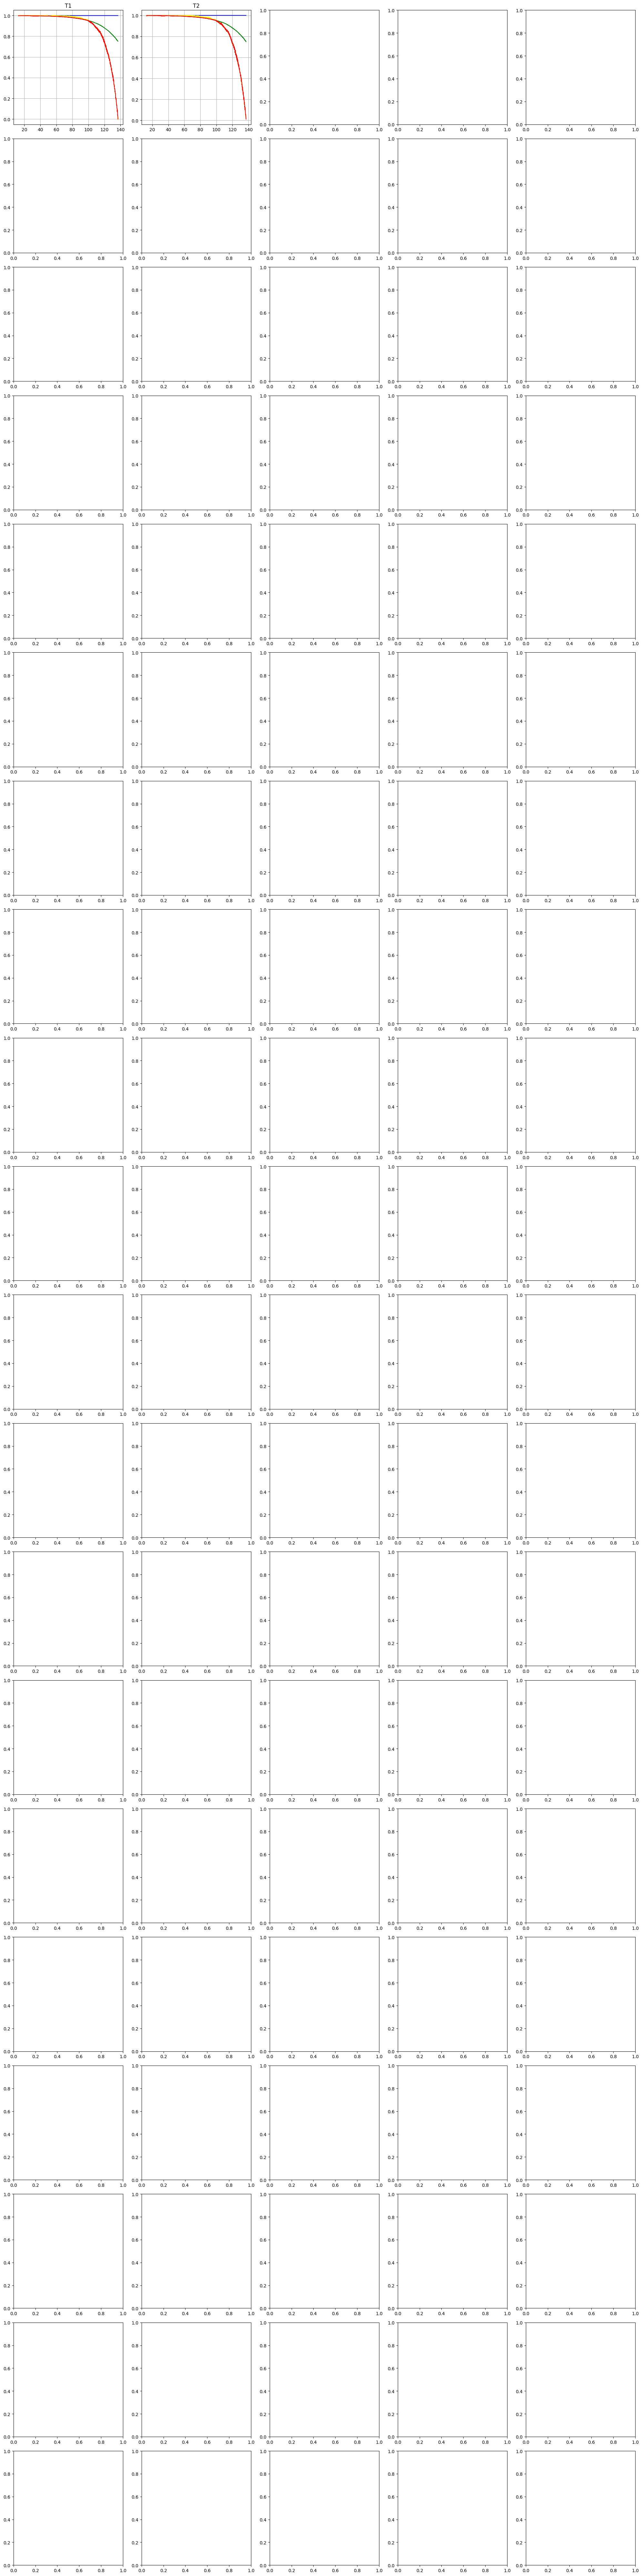

In [13]:
plot1 = MatPlot() 
plot1.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX= timeDraw, color=['green','blue', 'yellow','red'], numRow=20, numCol=5)

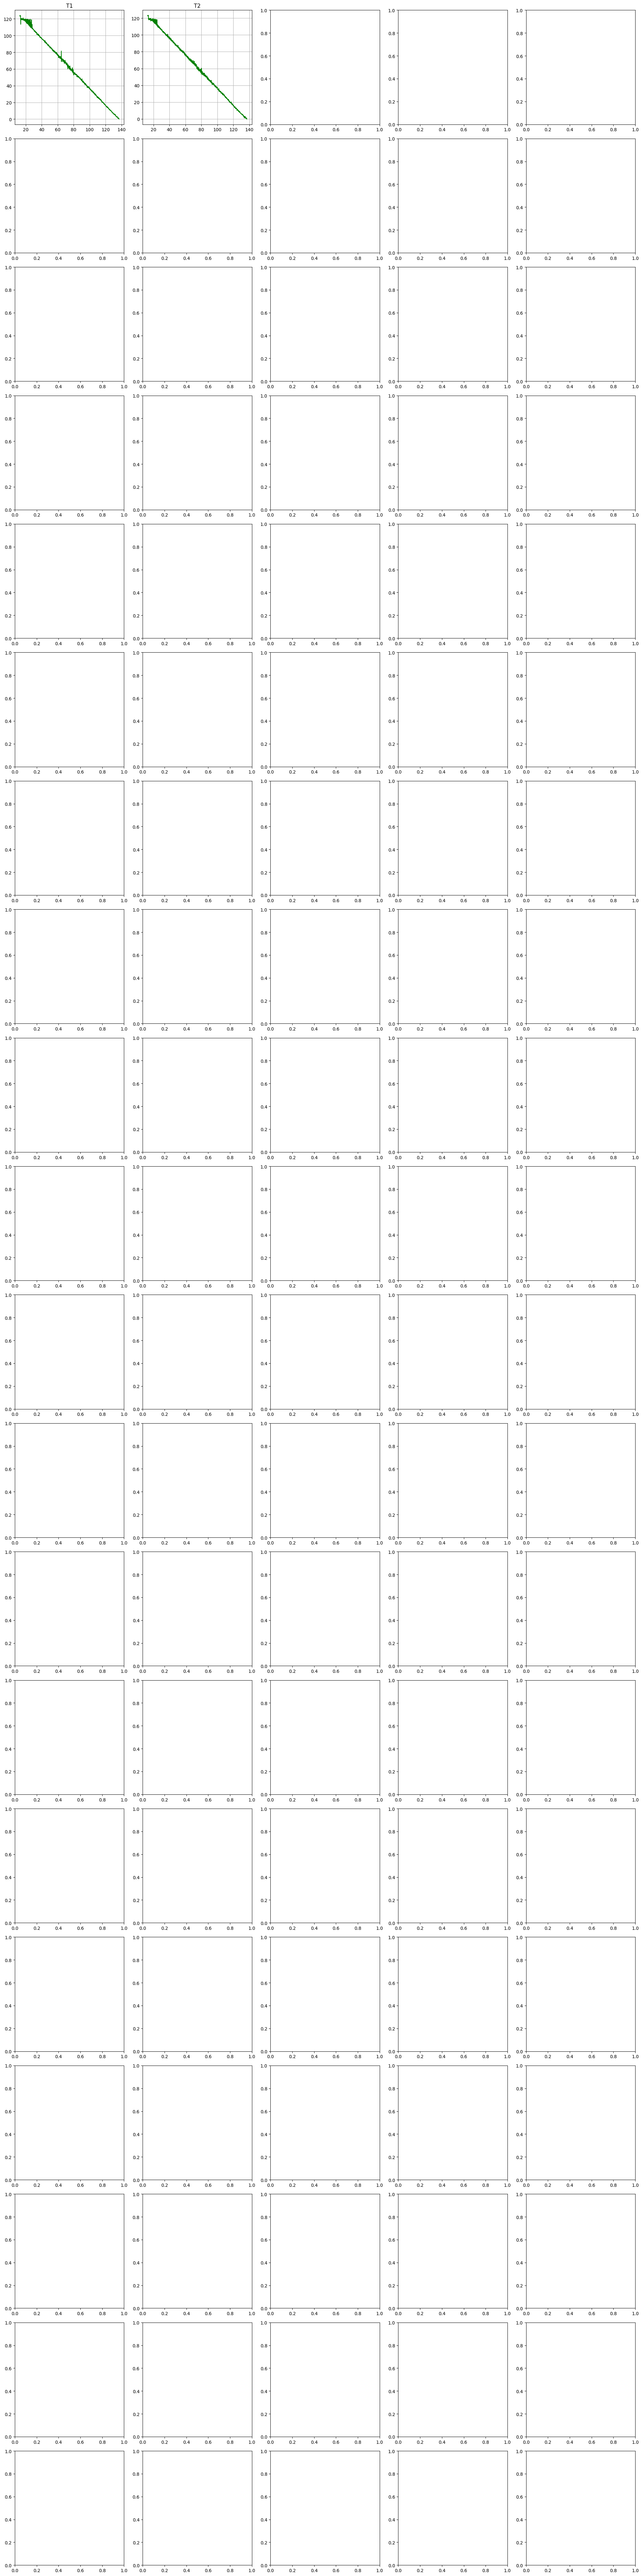

In [14]:
plot2 = MatPlot()
plot2.subPlotMultiImg(inY = [rulEnv1["Sys"]], inX=timeDraw,color=['g'], numRow=20, numCol=5)

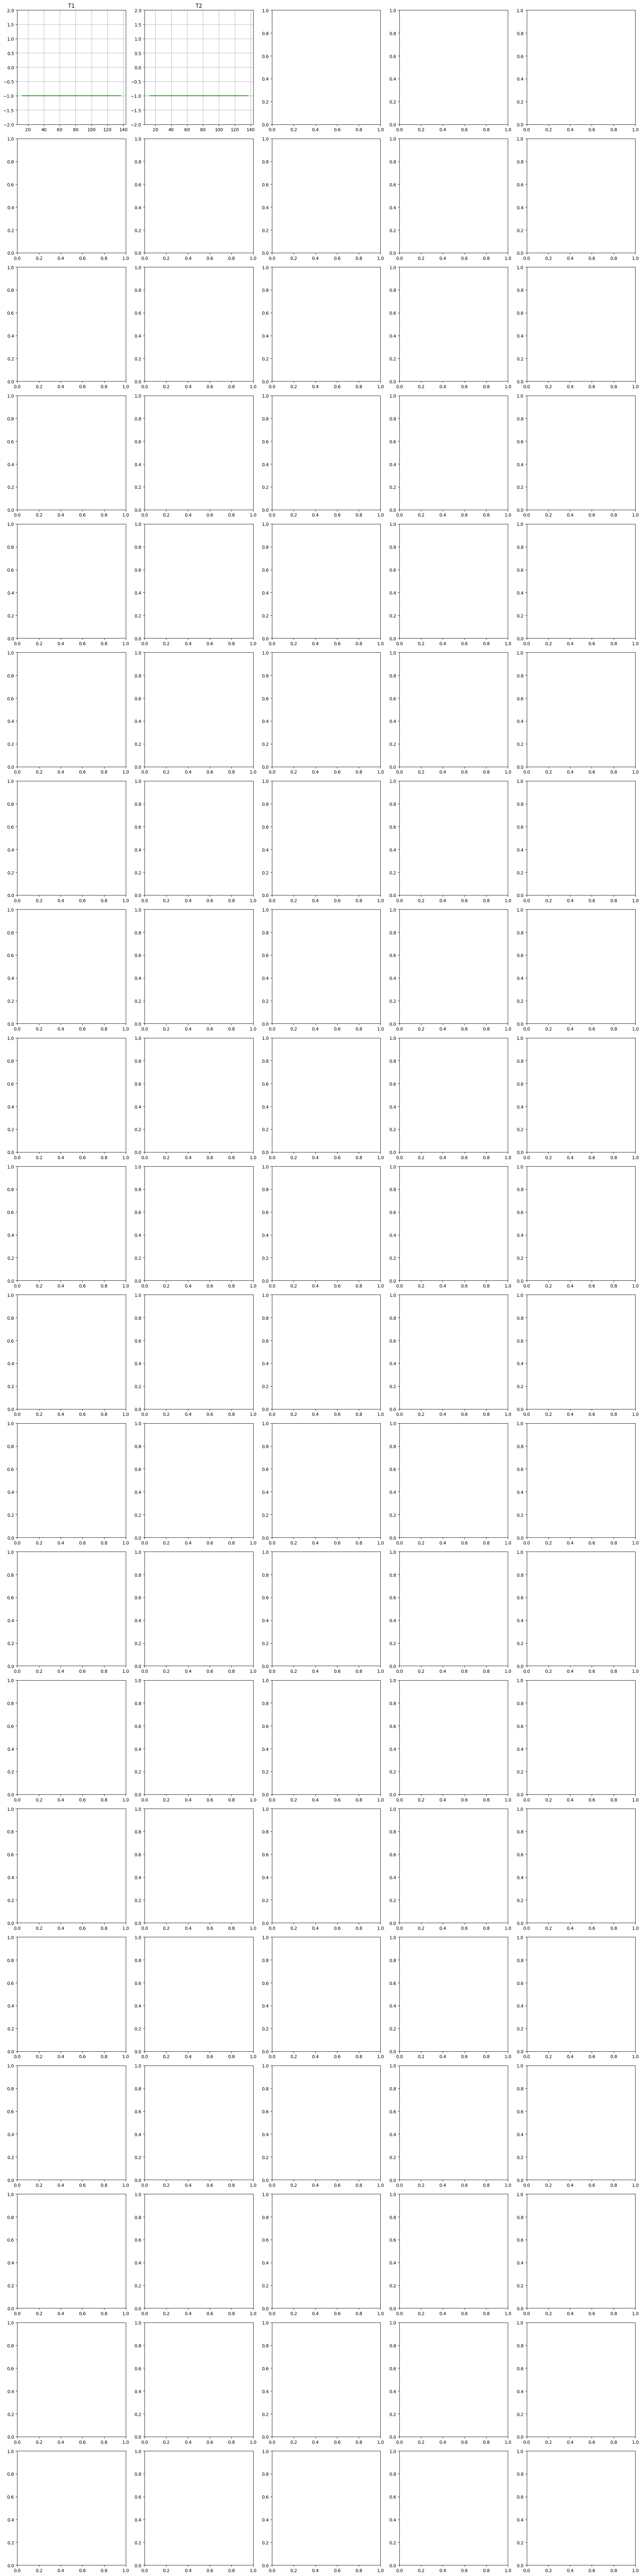

In [15]:
lookup = {0: -1, 1: 1, 2: 0}
showMatrix = []
for idxMulMatrix in hiEnv1["multipliedMatrix"]:
    signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
    showMatrix.append(signal)

plot2 = MatPlot()
plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])

#### Environment 3

In [16]:
environmentIdx      = 3
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # print(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:18633||2025-02-17 10:53:46,755-INFO [preProcessingDataTEP.py:getTensorData():784]:Spliting data into sequences now ...


Getting the HI at the idx 1


Process:18633||2025-02-17 10:53:47,009-DEBUG [preProcessingDataTEP.py:getTensorData():849]:The shape of the tensor is (1295, 128, 48)
Process:18633||2025-02-17 10:53:47,599-INFO [preProcessingDataTEP.py:getTensorData():784]:Spliting data into sequences now ...
Process:18633||2025-02-17 10:53:47,670-DEBUG [preProcessingDataTEP.py:getTensorData():849]:The shape of the tensor is (1281, 128, 48)


Getting the HI at the idx 2


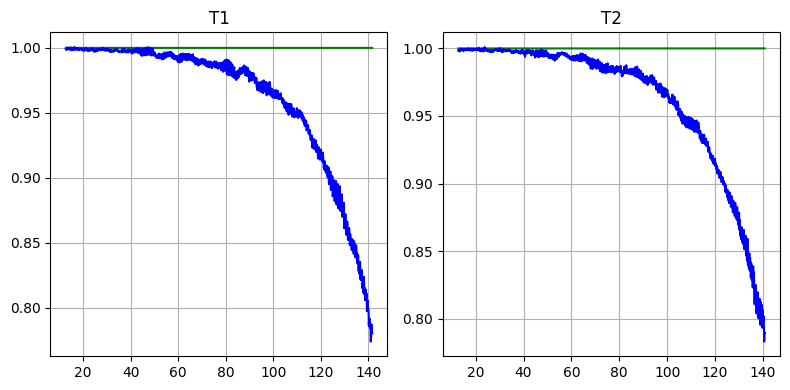

In [19]:
plot3 = MatPlot() 
plot3.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"]], inX=timeDraw, color=['g','b'], numRow=1, numCol=2)

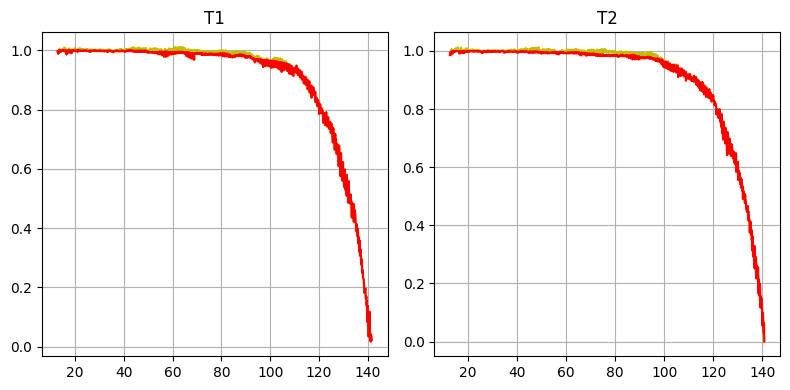

In [18]:
plot3 = MatPlot() 
plot3.subPlotMultiImg(inY = [ hiEnv1["Strip"],hiEnv1["Sys"]], inX=timeDraw, color=[ 'y','r'], numRow=1, numCol=2)

In [ ]:
plot4 = MatPlot()
plot4.subPlotMultiImg(inY = [ rulEnv1["Sys"]],  inX=timeDraw, color=['g'], numRow=20, numCol=5)

In [ ]:
lookup = {0: -1, 1: 1, 2: 0}
showMatrix = []
for idxMulMatrix in hiEnv1["multipliedMatrix"]:
    signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
    showMatrix.append(signal)

plot2 = MatPlot()
plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])

#### Environment 4

In [ ]:
environmentIdx      = 4
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # print(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


In [ ]:
plot5 = MatPlot() 
plot1.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX= timeDraw, color=['green','blue', 'yellow','red'], numRow=20, numCol=5)

In [ ]:
plot6 = MatPlot()
plot6.subPlotMultiImg(inY = [rulEnv1["Sys"]], inX=timeDraw, color=['g'], numRow=20, numCol=5)

In [ ]:
lookup = {0: -1, 1: 1, 2: 0}
showMatrix = []
for idxMulMatrix in hiEnv1["multipliedMatrix"]:
    signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
    showMatrix.append(signal)

plot2 = MatPlot()
plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])